#  Klasifikasi dan Regresi Lokalisasi Indoor Berbasis RSSI Wi-Fi

Tim R&D PT. Sinyal Nusantara sedang mengembangkan layanan navigasi di dalam gedung untuk sebuah kampus besar. GPS tidak andal di dalam ruangan, sehingga posisi pengguna harus diperkirakan dari kekuatan sinyal (RSSI) access point Wi-Fi yang tertangkap ponsel. 
Ibu Laras, manajer produk, ingin tahu apakah sidik jari (fingerprint) RSSI cukup untuk menebak gedung dan lantai pengguna, sekaligus memperkirakan koordinatnya dengan galat sekecil mungkin.

## PROSES 1 — EDA DAN DATA PREPROCESSING

**Aturan evaluasi:** EDA dan preprocessing yang mempelajari parameter hanya menggunakan `trainingData`. `validationData` disimpan sebagai data uji tambahan dan tidak digunakan sampai evaluasi akhir. Seluruh imputasi, seleksi fitur, dan scaling yang membutuhkan `fit` dilakukan di dalam Pipeline setelah train-test split.

### 1. Import Library

Mengimpor library untuk manipulasi data, visualisasi, statistik, dan preprocessing.

In [1]:
# Cell 1: Import Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings('ignore')

# Konfigurasi visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

RANDOM_STATE = 42

print("Library berhasil diimpor.")

Library berhasil diimpor.


### 2. Load dataset

Tujuan: Membaca dataset training dan validation. Validation hanya dimuat dan disimpan. Sesuai aturan eksperimen, isinya tidak diperiksa, tidak digunakan untuk preprocessing, dan tidak digunakan untuk pemilihan model sampai evaluasi akhir.

In [2]:
from pathlib import Path

# Sesuaikan dengan struktur folder lokal.
train_candidates = [
    Path("data/trainingData.csv"),
    Path("trainingData.csv"),
    Path("/mnt/data/trainingData(2).csv")
]
validation_candidates = [
    Path("data/validationData.csv"),
    Path("validationData.csv"),
    Path("/mnt/data/validationData(2).csv")
]

train_path = next((p for p in train_candidates if p.exists()), None)
validation_path = next((p for p in validation_candidates if p.exists()), None)

if train_path is None:
    raise FileNotFoundError(
        "File trainingData.csv tidak ditemukan. Letakkan file di folder data/."
    )
if validation_path is None:
    raise FileNotFoundError(
        "File validationData.csv tidak ditemukan. Letakkan file di folder data/."
    )

df_train = pd.read_csv(train_path)
df_validation = pd.read_csv(validation_path)

print("Training Dataset:", df_train.shape)
print("Validation dataset berhasil dimuat dan disimpan untuk evaluasi akhir.")
print("Validation tidak digunakan pada EDA, preprocessing, atau pemilihan model.")
display(df_train.head())

Training Dataset: (19937, 529)
Validation dataset berhasil dimuat dan disimpan untuk evaluasi akhir.
Validation tidak digunakan pada EDA, preprocessing, atau pemilihan model.


,WAP001,WAP002,WAP003,WAP004,WAP005,WAP006,WAP007,WAP008,WAP009,WAP010,...,WAP520,LONGITUDE,LATITUDE,FLOOR,BUILDINGID,SPACEID,RELATIVEPOSITION,USERID,PHONEID,TIMESTAMP
0,100,100,100,100,100,100,100,100,100,100,...,100,-7541.2643,4.864921e+06,2,1,106,2,2,23,1371713733
1,100,100,100,100,100,100,100,100,100,100,...,100,-7536.6212,4.864934e+06,2,1,106,2,2,23,1371713691
2,100,100,100,100,100,100,100,-97,100,100,...,100,-7519.1524,4.864950e+06,2,1,103,2,2,23,1371714095
3,100,100,100,100,100,100,100,100,100,100,...,100,-7524.5704,4.864934e+06,2,1,102,2,2,23,1371713807
4,100,100,100,100,100,100,100,100,100,100,...,100,-7632.1436,4.864982e+06,0,0,122,2,11,13,1369909710


### 3. Identifikasi kolom
Tujuan: Memisahkan fitur RSSI, target, dan metadata.

Disini tidak boleh menggunakan USERID, PHONEID, dan TIMESTAMP sebagai fitur prediksi posisi karena dapat menyebabkan model mempelajari identitas perangkat atau pola waktu, bukan fingerprint Wi-Fi.

Catatan: SPACEID dan RELATIVEPOSITION juga tidak kita gunakan sebagai fitur prediksi utama. Keduanya berpotensi memberikan informasi lokasi secara langsung.

In [3]:
# Fitur RSSI
rssi_features = [
    col for col in df_train.columns
    if col.startswith("WAP")
]

# Target klasifikasi
classification_targets = [
    "BUILDINGID",
    "FLOOR"
]

# Target regresi
regression_targets = [
    "LONGITUDE",
    "LATITUDE"
]

# Metadata
metadata_features = [
    "SPACEID",
    "RELATIVEPOSITION",
    "USERID",
    "PHONEID",
    "TIMESTAMP"
]

print("Jumlah fitur RSSI:", len(rssi_features))
print("Target klasifikasi:", classification_targets)
print("Target regresi:", regression_targets)
print("Metadata:", metadata_features)

assert len(rssi_features) == 520

Jumlah fitur RSSI: 520
Target klasifikasi: ['BUILDINGID', 'FLOOR']
Target regresi: ['LONGITUDE', 'LATITUDE']
Metadata: ['SPACEID', 'RELATIVEPOSITION', 'USERID', 'PHONEID', 'TIMESTAMP']


### 4. Pemeriksaan struktur dataset

Tujuan: Memeriksa struktur dan tipe data pada training. Dataset validation disimpan sebagai data uji tambahan dan tidak diperiksa pada tahap EDA/preprocessing.

In [4]:
print("=== TRAINING DATA ===")
df_train.info()

print("\\n=== TIPE DATA TRAINING ===")
display(df_train.dtypes.value_counts())

print("\\nJumlah kolom training:", len(df_train.columns))

=== TRAINING DATA ===
<class 'pandas.DataFrame'>
RangeIndex: 19937 entries, 0 to 19936
Columns: 529 entries, WAP001 to TIMESTAMP
dtypes: float64(2), int64(527)
memory usage: 80.5 MB
\n=== TIPE DATA TRAINING ===


int64      527
float64      2
Name: count, dtype: int64

\nJumlah kolom training: 529


### 5. Pemeriksaan duplikasi
Tujuan: Mengidentifikasi baris yang memiliki seluruh nilai sama.

In [5]:
duplicate_train = df_train.duplicated().sum()
duplicate_validation = df_validation.duplicated().sum()

print("Duplikasi training:", duplicate_train)
print("Duplikasi validation:", duplicate_validation)

print(
    "Persentase duplikasi training:",
    round(duplicate_train / len(df_train) * 100, 2),
    "%"
)

Duplikasi training: 637
Duplikasi validation: 0
Persentase duplikasi training: 3.2 %


### 6. Missing value aktual

Tujuan: Memeriksa nilai kosong pada data training. Validation tidak disentuh sampai evaluasi akhir.

In [6]:
# Missing value hanya diperiksa pada data training.
missing_train = df_train.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Training": missing_train
})

missing_summary = missing_summary[
    missing_summary["Missing Training"] > 0
]

print("Total missing training:", missing_train.sum())
display(missing_summary)

Total missing training: 0


,Missing Training


### 7. Analisis nilai RSSI +100

Tujuan: Mengukur jumlah dan persentase WAP yang tidak terdeteksi pada data training. Validation tetap disimpan untuk evaluasi akhir.

In [7]:
# Sentinel RSSI hanya dianalisis pada data training.
rssi_train = df_train[rssi_features]

sentinel_count = (rssi_train == 100).sum()
sentinel_percentage = (rssi_train == 100).mean() * 100

sentinel_summary = pd.DataFrame({
    "WAP": rssi_features,
    "Sentinel Count": sentinel_count.values,
    "Sentinel Percentage": sentinel_percentage.values
})

sentinel_summary = sentinel_summary.sort_values(
    by="Sentinel Percentage",
    ascending=False
)

display(sentinel_summary.head(15))

print(
    "Rata-rata persentase sentinel training:",
    round(sentinel_percentage.mean(), 2),
    "%"
)

,WAP,Sentinel Count,Sentinel Percentage
519,WAP520,19937,100.0
496,WAP497,19937,100.0
490,WAP491,19937,100.0
486,WAP487,19937,100.0
487,WAP488,19937,100.0
484,WAP485,19937,100.0
481,WAP482,19937,100.0
246,WAP247,19937,100.0
450,WAP451,19937,100.0
457,WAP458,19937,100.0


Rata-rata persentase sentinel training: 96.54 %


### 8. Visualisasi Missing RSSI

Visualisasi ini membantu mengetahui apakah sebagian besar access point memiliki tingkat deteksi yang sangat rendah.
informasi ini digunakan untuk menentukan strategi seleksi fitur.

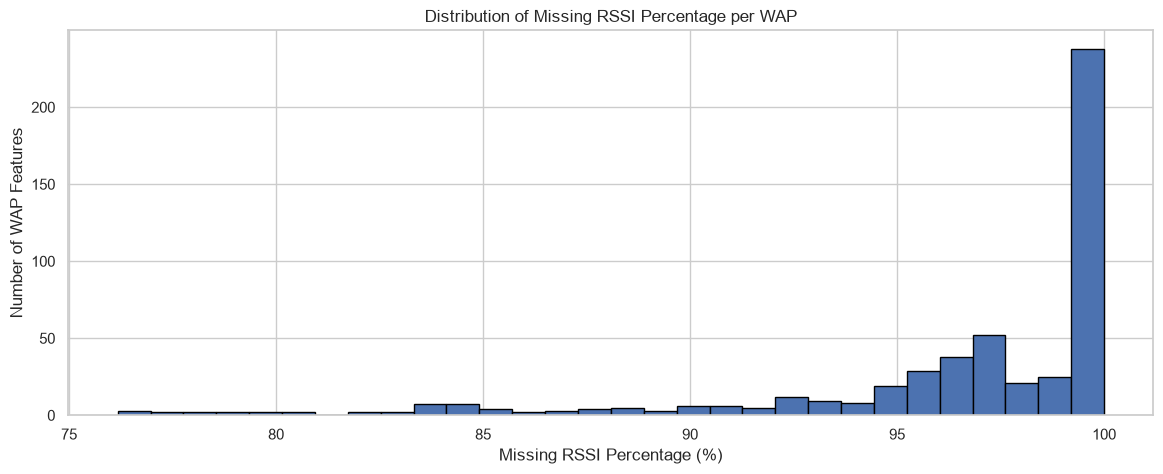

In [8]:
plt.figure(figsize=(14, 5))

plt.hist(
    sentinel_percentage,
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Missing RSSI Percentage per WAP")
plt.xlabel("Missing RSSI Percentage (%)")
plt.ylabel("Number of WAP Features")

plt.show()

### 9. Identifikasi WAP konstan

Tujuan: Menemukan fitur RSSI yang tidak memiliki variasi pada training sebagai bagian dari EDA. Daftar ini hanya untuk pelaporan. Penghapusan fitur untuk model dilakukan setelah split melalui `VarianceThreshold` di dalam Pipeline agar tidak terjadi data leakage.

In [9]:
constant_features = [
    col for col in rssi_features
    if df_train[col].nunique() == 1
]

print("Jumlah fitur konstan:", len(constant_features))
print("Daftar fitur konstan:")
print(constant_features)

print(
    "Persentase fitur konstan:",
    round(len(constant_features) / len(rssi_features) * 100, 2),
    "%"
)

Jumlah fitur konstan: 55
Daftar fitur konstan:
['WAP003', 'WAP004', 'WAP092', 'WAP093', 'WAP094', 'WAP095', 'WAP152', 'WAP158', 'WAP159', 'WAP160', 'WAP215', 'WAP217', 'WAP226', 'WAP227', 'WAP238', 'WAP239', 'WAP240', 'WAP241', 'WAP242', 'WAP243', 'WAP244', 'WAP245', 'WAP246', 'WAP247', 'WAP254', 'WAP293', 'WAP296', 'WAP301', 'WAP303', 'WAP304', 'WAP307', 'WAP333', 'WAP349', 'WAP353', 'WAP360', 'WAP365', 'WAP416', 'WAP419', 'WAP423', 'WAP429', 'WAP433', 'WAP438', 'WAP441', 'WAP442', 'WAP444', 'WAP445', 'WAP451', 'WAP458', 'WAP482', 'WAP485', 'WAP487', 'WAP488', 'WAP491', 'WAP497', 'WAP520']
Persentase fitur konstan: 10.58 %


### 10. Distribusi BUILDINGID
Tujuan: Mengetahui jumlah sampel setiap kelas gedung.

BUILDINGID
0    5249
1    5196
2    9492
Name: count, dtype: int64


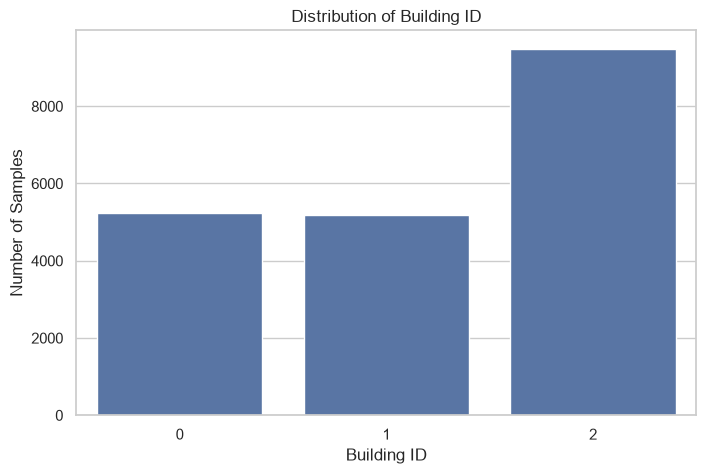

In [10]:
building_counts = df_train["BUILDINGID"].value_counts().sort_index()

print(building_counts)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_train,
    x="BUILDINGID",
    order=sorted(df_train["BUILDINGID"].unique())
)

plt.title("Distribution of Building ID")
plt.xlabel("Building ID")
plt.ylabel("Number of Samples")

plt.show()

### 11. Distribusi FLOOR
Tujuan: Memeriksa distribusi kelas lantai.

FLOOR
0    4369
1    5002
2    4416
3    5048
4    1102
Name: count, dtype: int64


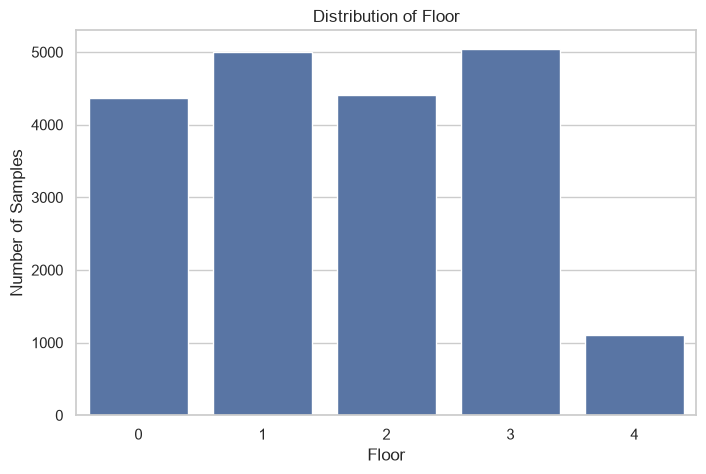

In [11]:
floor_counts = df_train["FLOOR"].value_counts().sort_index()

print(floor_counts)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_train,
    x="FLOOR",
    order=sorted(df_train["FLOOR"].unique())
)

plt.title("Distribution of Floor")
plt.xlabel("Floor")
plt.ylabel("Number of Samples")

plt.show()

### 12. Statistik deskriptif RSSI
Tujuan: Mengetahui karakteristik nilai RSSI, termasuk nilai minimum, maksimum, rata-rata, median, dan standar deviasi.

Penting: nilai +100 masih dianggap sebagai sentinel, sehingga kita keluarkan sementara dari statistik RSSI aktual.

Interpretasi:
- mean: rata-rata kekuatan sinyal.
- std: variasi kekuatan sinyal.
- min dan max: rentang nilai RSSI yang terdeteksi.
- 50%: median RSSI.

Nilai count menunjukkan jumlah observasi RSSI yang benar-benar terdeteksi.

In [12]:
rssi_clean_eda = df_train[rssi_features].replace(100, np.nan)

rssi_statistics = rssi_clean_eda.describe().T


rssi_statistics[
     ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]
].round(2)


,count,mean,std,min,25%,50%,75%,max
WAP001,18.0,-95.33,1.14,-97.0,-96.0,-96.0,-94.25,-93.0
WAP002,19.0,-87.89,2.05,-90.0,-90.0,-86.0,-86.00,-86.0
WAP003,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WAP004,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WAP005,40.0,-92.52,2.15,-97.0,-94.0,-92.0,-91.75,-89.0
...,...,...,...,...,...,...,...,...
WAP516,3038.0,-72.56,14.61,-101.0,-84.0,-74.0,-63.00,0.0
WAP517,4543.0,-76.02,12.06,-101.0,-85.0,-77.0,-70.00,0.0
WAP518,22.0,-91.55,3.73,-97.0,-95.0,-91.0,-88.00,-87.0
WAP519,3.0,-96.00,1.73,-97.0,-97.0,-97.0,-95.50,-94.0


### 13. Distribusi nilai RSSI
Tujuan: Melihat pola distribusi kekuatan sinyal Wi-Fi.

Interpretasi:
Distribusi ini membantu mengetahui rentang RSSI yang paling sering diterima perangkat.
Semakin mendekati 0 dBm, sinyal semakin kuat. Semakin negatif nilainya, sinyal semakin lemah.

In [13]:
plt.figure(figsize=(12, 6))

plt.hist(
    rssi_values,
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of RSSI Values")
plt.xlabel("RSSI (dBm)")
plt.ylabel("Frequency")

plt.show()

NameError: name 'rssi_values' is not defined

<Figure size 1200x600 with 0 Axes>

### 14. Distribusi RSSI berdasarkan gedung
Tujuan: Mengidentifikasi apakah karakteristik fingerprint RSSI berbeda antar gedung.

Interpretasi:
Apabila distribusi RSSI berbeda antar gedung, fingerprint Wi-Fi berpotensi memberikan informasi yang berguna untuk klasifikasi gedung.

In [ ]:
sample_size = min(5, len(rssi_features))

selected_waps = (
    df_train[rssi_features]
    .replace(100, np.nan)
    .notna()
    .sum()
    .sort_values(ascending=False)
    .head(sample_size)
    .index
)

plot_data = df_train[
    list(selected_waps) + ["BUILDINGID"]
].melt(
    id_vars="BUILDINGID",
    var_name="WAP",
    value_name="RSSI"
)

plot_data = plot_data[plot_data["RSSI"] != 100]

g = sns.catplot(
    data=plot_data,
    x="BUILDINGID",
    y="RSSI",
    col="WAP",
    kind="box",
    col_wrap=3,
    height=4,
    sharey=True
)

g.set_axis_labels("Building ID", "RSSI (dBm)")
g.fig.suptitle(
    "RSSI Distribution Across Buildings",
    y=1.03
)

plt.show()

### 15. Deteksi outlier menggunakan IQR
Tujuan: Mengidentifikasi nilai RSSI ekstrem menggunakan metode Interquartile Range (IQR).

Rumus:

IQR = Q3 - Q1

Lower = Q1 - 1,5(IQR)

Upper = Q3 + 1,5(IQR)

ini berfungsi untuk menghitung outlier hanya dari RSSI yang terdeteksi, bukan sentinel +100.

Interpretasi:

Jangan langsung menghapus outlier yang terdeteksi.

Dalam konteks RSSI, nilai ekstrem dapat menjadi karakteristik fingerprint suatu lokasi. Dalam hal ini harus membedakan anomali pengukuran dengan variasi sinyal yang memang valid.

In [ ]:
outlier_results = []

for col in rssi_features:

    values = df_train[col]
    values = values[values != 100]

    if len(values) == 0:
        continue

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (values < lower_bound) |
        (values > upper_bound)
    ).sum()

    outlier_results.append({
        "WAP": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outliers,
        "Outlier Percentage": outliers / len(values) * 100
    })

outlier_df = pd.DataFrame(outlier_results)


outlier_df.sort_values(
    "Outlier Percentage",
     ascending=False
 ).head(20).round(2)


### 16. Visualisasi outlier



In [ ]:
selected_outlier_waps = outlier_df.nlargest(
    6,
    "Outlier Percentage"
)["WAP"].tolist()

boxplot_data = df_train[selected_outlier_waps].replace(
    100,
    np.nan
)

plt.figure(figsize=(13, 6))

sns.boxplot(data=boxplot_data)

plt.title("RSSI Outlier Detection Using Boxplot")
plt.xlabel("WAP Features")
plt.ylabel("RSSI (dBm)")

plt.xticks(rotation=45)
plt.show()

### 17. Korelasi antarfitur RSSI
Tujuan: Mengetahui hubungan antar-WAP. Fitur yang memiliki korelasi tinggi mungkin membawa informasi yang serupa.

Untuk menjaga visualisasi tetap terbaca, gunakan 30 WAP dengan variasi terbesar setelah sentinel diubah menjadi NaN.

Interpretasi:
- Korelasi mendekati +1: hubungan positif kuat.
- Korelasi mendekati -1: hubungan negatif kuat.
- Korelasi mendekati 0: hubungan linear lemah.

Korelasi tinggi tidak otomatis berarti salah satu fitur harus dihapus.

In [ ]:
rssi_variance = (
    rssi_clean_eda
    .var()
    .sort_values(ascending=False)
)

top_30_waps = rssi_variance.head(30).index

correlation_matrix = (
    rssi_clean_eda[top_30_waps]
    .corr()
)

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Correlation Heatmap of Top 30 WAP Features")
plt.show()

### 18. Korelasi fitur dengan koordinat
Tujuan: Mengevaluasi hubungan linear RSSI dengan koordinat LONGITUDE dan LATITUDE.

Catatan: Korelasi Pearson hanya mengukur hubungan linear. Hubungan spasial yang lebih kompleks belum tentu terlihat melalui korelasi ini.

In [ ]:
correlation_data = df_train[
    list(top_30_waps) + [
        "LONGITUDE",
        "LATITUDE"
    ]
].replace(100, np.nan)

target_correlation = (
    correlation_data.corr()[["LONGITUDE", "LATITUDE"]]
    .iloc[:-2]
)

display(
    target_correlation
    .sort_values("LONGITUDE", ascending=False)
    .head(15)
)

plt.figure(figsize=(8, 12))

sns.heatmap(
    target_correlation,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("RSSI Correlation with Coordinates")
plt.show()

### 19. Distribusi koordinat LONGITUDE dan LATITUDE
Tujuan: Memahami sebaran posisi pengguna berdasarkan koordinat geografis.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_train["LONGITUDE"], bins=40, edgecolor="black")
axes[0].set_title("Longitude Distribution")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Frequency")

axes[1].hist(df_train["LATITUDE"], bins=40, edgecolor="black")
axes[1].set_title("Latitude Distribution")
axes[1].set_xlabel("Latitude")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### 20. Visualisasi sebaran lokasi

Interpretasi:

Visualisasi ini membantu melihat apakah koordinat antar gedung membentuk kelompok spasial yang berbeda.

In [ ]:
plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=df_train,
    x="LONGITUDE",
    y="LATITUDE",
    hue="BUILDINGID",
    style="FLOOR",
    alpha=0.5,
    s=25
)

plt.title("Indoor Location Distribution")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

### 21. Membuat salinan dataset
Tujuan: Mempertahankan dataset asli agar tidak berubah selama proses preprocessing.

In [ ]:
# Salinan fitur dan target training.
# df_validation sengaja tidak diproses sampai evaluasi akhir.
X_train_raw = df_train[rssi_features].copy()

y_train = df_train[
    ["BUILDINGID", "FLOOR", "LONGITUDE", "LATITUDE"]
].copy()

print("Training features:", X_train_raw.shape)
print("Training targets:", y_train.shape)
print("Validation tetap tidak disentuh.")

### 22. Metode 1: Sentinel replacement (-105 dBm)
Tujuan: Mengganti nilai +100 dengan -105 dBm.

Alasannya:
- RSSI yang tidak terdeteksi bukan berarti sinyal kuat.
- Nilai -105 dBm berada sedikit di bawah batas minimum RSSI yang tercatat.
- Metode ini mempertahankan informasi bahwa WAP tidak terdeteksi melalui nilai yang sangat rendah.

Catatan: Metode ini tidak memerlukan proses fitting. Namun, -105 merupakan keputusan domain yang perlu diuji dampaknya terhadap performa model.

In [ ]:
# Metode 1: mengganti sentinel +100 dengan -105 dBm.
# Transformasi ini deterministik dan tidak mempelajari parameter dari data.
X_train_m1 = X_train_raw.replace(100, -105)

print("Jumlah sentinel +100 tersisa:",
      (X_train_m1 == 100).sum().sum())
print("Training shape:", X_train_m1.shape)
display(X_train_m1.head())

### 23. Metode 2: Sentinel menjadi NaN dan imputasi median
Tujuan: Mengganti nilai tidak terdeteksi menjadi NaN, lalu mengisi nilai tersebut menggunakan median setiap WAP.

Median dihitung hanya dari training. Validation menggunakan median yang sama.

Interpretasi:

Metode median memberikan nilai pengganti berdasarkan RSSI yang terdeteksi. Namun, metode ini dapat menghilangkan informasi tentang apakah WAP sebenarnya tidak terdeteksi.

Karena itu, kita tidak boleh langsung menganggap metode median lebih baik daripada -105 dBm.

In [ ]:
# Metode 2: ubah sentinel +100 menjadi NaN.
# Imputer BELUM di-fit di sini. Median baru dipelajari setelah train-test split.
X_train_m2 = X_train_raw.replace(100, np.nan)

print("Shape sebelum imputasi:", X_train_m2.shape)
print("Jumlah NaN:", X_train_m2.isna().sum().sum())
print("Jumlah fitur seluruhnya NaN:",
      X_train_m2.columns[X_train_m2.isna().all()].size)

print("Imputasi median akan dilakukan di dalam Pipeline setelah split.")

### 24. Membandingkan kedua metode
Tujuan: Melihat perbedaan statistik hasil preprocessing.

Interpretasi: Perubahan mean dan standar deviasi menunjukkan bahwa strategi penanganan nilai tidak terdeteksi memengaruhi karakteristik data.

In [ ]:
# Perbandingan awal sifat representasi missing.
# Perbandingan performa yang adil dilakukan setelah split dengan pipeline terpisah.

method_comparison = pd.DataFrame({
    "Method": ["Sentinel replacement (-105)", "NaN + Median Imputation"],
    "Representation before model": [
        "Nilai tidak terdeteksi direpresentasikan sebagai -105",
        "Nilai tidak terdeteksi menjadi NaN; median dipelajari dari training split"
    ],
    "Requires fitted parameter": [
        "Tidak",
        "Ya, median per fitur"
    ],
    "Data used to fit": [
        "Tidak ada",
        "Hanya training split"
    ]
})

display(method_comparison)

### 25. Pemeriksaan fitur konstan

Tujuan: Melaporkan fitur yang tidak memiliki variasi pada seluruh training. Daftar ini tidak digunakan langsung untuk membangun data model karena seleksi fitur harus dipelajari hanya dari training split di dalam Pipeline.

In [ ]:
# Laporan eksploratif fitur konstan pada keseluruhan training.
# Jangan gunakan daftar ini untuk membuang fitur sebelum split.
# Seleksi fitur model dilakukan dengan VarianceThreshold di dalam Pipeline.

constant_features_eda = [
    col for col in rssi_features
    if X_train_raw[col].nunique(dropna=False) == 1
]

print("Fitur konstan pada keseluruhan training (laporan EDA):",
      len(constant_features_eda))
print("Daftar:", constant_features_eda)
print("Catatan: daftar ini tidak dipakai untuk seleksi fitur model.")

### 26. Membandingkan full features dan reduced features

Catatan: Reduced features di sini hanya menghapus fitur konstan. Disini belum melakukan PCA atau seleksi berdasarkan korelasi.

In [ ]:
feature_comparison_plan = pd.DataFrame({
    "Scenario": ["Full features", "Reduced features"],
    "Feature selection": [
        "520 fitur RSSI dipertahankan",
        "VarianceThreshold(threshold=0) di-fit hanya pada training split"
    ],
    "Leakage control": [
        "Preprocessing di-fit hanya pada training split",
        "Seleksi fitur dan scaler berada di dalam Pipeline"
    ]
})

display(feature_comparison_plan)

### 27. Encoding target kategorikal

BUILDINGID dan FLOOR pada dataset ini sudah berupa label numerik. Keduanya dapat langsung digunakan sebagai target klasifikasi. LabelEncoder tidak diperlukan. Encoding target, jika dibutuhkan oleh model tertentu, harus dipelajari hanya dari label training split.

In [ ]:
# BUILDINGID dan FLOOR sudah berupa label kelas numerik.
# Tidak perlu LabelEncoder untuk target ini.
print("Building classes:", sorted(y_train["BUILDINGID"].unique()))
print("Floor classes:", sorted(y_train["FLOOR"].unique()))

### 28. Menghitung imbalance ratio
Tujuan: Mengukur tingkat ketidakseimbangan distribusi kelas.

Interpretasi:

Imbalance ratio dihitung menggunakan:

IR=Jumlah kelas mayoritas /
Jumlah kelas minoritas

Semakin besar nilainya, semakin besar perbedaan jumlah sampel antarkelas.

In [ ]:
def calculate_imbalance(target):

    counts = target.value_counts()

    imbalance_ratio = counts.max() / counts.min()

    result = pd.DataFrame({
        "Class": counts.index,
        "Count": counts.values,
        "Percentage": (
            counts.values / counts.sum()
        ) * 100
    })

    return result, imbalance_ratio


building_balance, building_ir = calculate_imbalance(
    y_train["BUILDINGID"]
)

floor_balance, floor_ir = calculate_imbalance(
    y_train["FLOOR"]
)

print("BUILDING DISTRIBUTION")
display(building_balance)

print("Building Imbalance Ratio:", round(building_ir, 3))

print("\nFLOOR DISTRIBUTION")
display(floor_balance)

print("Floor Imbalance Ratio:", round(floor_ir, 3))

### 29. Visualisasi imbalance

Untuk sementara, disini belum menerapkan SMOTE. Perlu mempertimbangkan pembagian data dan pipeline terlebih dahulu agar tidak terjadi data leakage.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(
    data=df_train,
    x="BUILDINGID",
    ax=axes[0]
)

axes[0].set_title("Building Class Distribution")

sns.countplot(
    data=df_train,
    x="FLOOR",
    ax=axes[1]
)

axes[1].set_title("Floor Class Distribution")

plt.tight_layout()
plt.show()

### 30. Membuat pembagian data 80:20 dan 70:30

Tujuan: Membuat dua skenario split dari trainingData. ValidationData tetap disimpan dan tidak digunakan. Stratifikasi memakai kombinasi BUILDINGID dan FLOOR agar komposisi pasangan kelas tetap terjaga.

In [ ]:
# Stratifikasi kombinasi gedung dan lantai.
# Semua kombinasi memiliki jumlah sampel yang cukup untuk kedua split.
stratify_target = (
    y_train["BUILDINGID"].astype(str)
    + "_"
    + y_train["FLOOR"].astype(str)
)

# Split 80:20
X_train_80, X_test_80, y_train_80, y_test_80 = train_test_split(
    X_train_raw,
    y_train,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=stratify_target
)

# Split 70:30
X_train_70, X_test_70, y_train_70, y_test_70 = train_test_split(
    X_train_raw,
    y_train,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=stratify_target
)

print("Split 80:20")
print("Train:", X_train_80.shape, "| Test:", X_test_80.shape)

print("\\nSplit 70:30")
print("Train:", X_train_70.shape, "| Test:", X_test_70.shape)

### 31. Membuat Pipeline untuk preprocessing

Tujuan: Menggabungkan transformasi sentinel/imputasi, seleksi fitur opsional, dan scaling. Semua komponen yang mempelajari parameter akan di-fit hanya pada training split.

In [ ]:
from sklearn.preprocessing import FunctionTransformer

def replace_sentinel_with_floor(X):
    """Mengganti sentinel +100 menjadi -105 tanpa mempelajari parameter."""
    if isinstance(X, pd.DataFrame):
        return X.replace(100, -105)
    X = np.asarray(X).copy()
    X[X == 100] = -105
    return X


def replace_sentinel_with_nan(X):
    """Mengganti sentinel +100 menjadi NaN tanpa mempelajari parameter."""
    if isinstance(X, pd.DataFrame):
        return X.replace(100, np.nan)
    X = np.asarray(X, dtype=float).copy()
    X[X == 100] = np.nan
    return X

def make_preprocessing_pipeline(method="sentinel", reduced=False,
                                scaler_type="standard"):
    """
    method:
      - 'sentinel': +100 diganti -105
      - 'median': +100 menjadi NaN lalu imputasi median

    reduced:
      - False: semua fitur dipertahankan
      - True: VarianceThreshold dipelajari dari training split
    """
    steps = []

    if method == "sentinel":
        steps.append((
            "sentinel_replacement",
            FunctionTransformer(
                replace_sentinel_with_floor,
                feature_names_out="one-to-one"
            )
        ))
    elif method == "median":
        steps.extend([
            ("sentinel_to_nan",
             FunctionTransformer(
                 replace_sentinel_with_nan,
                 feature_names_out="one-to-one"
             )),
            ("imputer",
             SimpleImputer(
                 strategy="median",
                 keep_empty_features=True
             ))
        ])
    else:
        raise ValueError("method harus 'sentinel' atau 'median'")

    if reduced:
        steps.append(("feature_selection", VarianceThreshold(threshold=0.0)))

    if scaler_type == "standard":
        steps.append(("scaler", StandardScaler()))
    elif scaler_type == "minmax":
        steps.append(("scaler", MinMaxScaler()))
    else:
        raise ValueError("scaler_type harus 'standard' atau 'minmax'")

    return Pipeline(steps)

### 32. Fit Pipeline pada training split

StandardScaler dan MinMaxScaler adalah alternatif eksperimen. Masing-masing harus di-fit secara terpisah pada training split. Jangan memilih scaler berdasarkan hasil test; pemilihan final dilakukan melalui validasi/CV pada data training.

In [ ]:
# Contoh perbandingan scaler pada skenario 80:20.
# Setiap scaler di-fit hanya pada X_train_80.

standard_pipeline = make_preprocessing_pipeline(
    method="sentinel",
    reduced=False,
    scaler_type="standard"
)

minmax_pipeline = make_preprocessing_pipeline(
    method="sentinel",
    reduced=False,
    scaler_type="minmax"
)

X_train_standard = standard_pipeline.fit_transform(X_train_80)
X_test_standard = standard_pipeline.transform(X_test_80)

X_train_minmax = minmax_pipeline.fit_transform(X_train_80)
X_test_minmax = minmax_pipeline.transform(X_test_80)

print("StandardScaler:", X_train_standard.shape, X_test_standard.shape)
print("MinMaxScaler:", X_train_minmax.shape, X_test_minmax.shape)

### 33. Membandingkan metode imputasi dan full vs reduced features

Tujuan: Membuat empat konfigurasi preprocessing yang konsisten pada split yang sama. Pipeline median dan seleksi fitur hanya di-fit pada training split. Test split hanya menerima transformasi.

In [ ]:
# Empat konfigurasi preprocessing untuk SETIAP skenario split.
# Semua komponen yang membutuhkan fit hanya belajar dari training split.
# ValidationData belum digunakan.

split_datasets = {
    "80_20": (X_train_80, X_test_80),
    "70_30": (X_train_70, X_test_70)
}

configuration_settings = {
    "sentinel_full": ("sentinel", False),
    "sentinel_reduced": ("sentinel", True),
    "median_full": ("median", False),
    "median_reduced": ("median", True)
}

fitted_preprocessing_pipelines = {}
preprocessed_shapes = []

for split_name, (Xtr, Xte) in split_datasets.items():
    for config_name, (method, reduced) in configuration_settings.items():

        pipeline = make_preprocessing_pipeline(
            method=method,
            reduced=reduced,
            scaler_type="standard"
        )

        Xtr_processed = pipeline.fit_transform(Xtr)
        Xte_processed = pipeline.transform(Xte)

        fitted_preprocessing_pipelines[
            (split_name, config_name)
        ] = pipeline

        preprocessed_shapes.append({
            "Split": split_name,
            "Configuration": config_name,
            "Train shape": Xtr_processed.shape,
            "Test shape": Xte_processed.shape
        })

display(pd.DataFrame(preprocessed_shapes))

print("Semua pipeline berhasil di-fit hanya pada training split.")
print("ValidationData belum digunakan.")

## Catatan audit dan batas tahap ini

- Analisis EDA menggunakan `trainingData` saja.
- `validationData` hanya dimuat. Jangan memanggil `head()`, `info()`, `describe()`, menghitung missing value, atau melakukan `transform()` pada validation sebelum evaluasi akhir.
- `+100` adalah sentinel tidak terdeteksi. Dua representasi yang dibandingkan adalah `-105` dan `NaN` + median.
- Median, seleksi fitur `VarianceThreshold`, dan scaler dipelajari hanya dari training split.
- Fitur konstan yang dihitung sebelum split hanya menjadi ringkasan EDA. Daftar tersebut tidak digunakan untuk membangun fitur model.
- BUILDINGID dan FLOOR sudah numerik, sehingga LabelEncoder tidak wajib.
- SMOTE belum diterapkan. Untuk klasifikasi multikelas, SMOTE harus ditempatkan di dalam imbalanced-learn Pipeline dan hanya dijalankan pada fold training.
- Perbandingan metode imputasi tidak dapat diputuskan dari mean/std saja. Gunakan split/CV yang sama dan bandingkan metrik model.
- Tahap ini belum mencakup eksperimen 6 model ML, 3 konfigurasi MLP, clustering, maupun evaluasi jarak posisi dalam meter.
